In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
from prophet import Prophet
import glob
import os

load the dataset

In [2]:
# Load CSV and Excel files
files = ["covid_19_clean_complete.csv"]

dataframes = []

for file in files:
    if file.endswith(".csv"):
        data = pd.read_csv(file)
    elif file.endswith((".xlsx", ".xls")):
        data = pd.read_excel(file)

    dataframes.append(data)

df = pd.concat(dataframes, ignore_index=True)

df["Date"] = pd.to_datetime(df["Date"])

print("Dataset loaded successfully!")
print("Shape:", df.shape)
print(df.head())

Dataset loaded successfully!
Shape: (49068, 10)
  Province/State Country/Region       Lat       Long       Date  Confirmed  \
0            NaN    Afghanistan  33.93911  67.709953 2020-01-22          0   
1            NaN        Albania  41.15330  20.168300 2020-01-22          0   
2            NaN        Algeria  28.03390   1.659600 2020-01-22          0   
3            NaN        Andorra  42.50630   1.521800 2020-01-22          0   
4            NaN         Angola -11.20270  17.873900 2020-01-22          0   

   Deaths  Recovered  Active             WHO Region  
0       0          0       0  Eastern Mediterranean  
1       0          0       0                 Europe  
2       0          0       0                 Africa  
3       0          0       0                 Europe  
4       0          0       0                 Africa  


Clean and prepare the data

In [3]:
# Check missing values
print(df.isnull().sum())

# Fill missing province names
df["Province/State"] = df["Province/State"].fillna("Unknown")

# Remove duplicate records
df = df.drop_duplicates()

# Sort data by country and date
df = df.sort_values(["Country/Region", "Date"])

print("Data cleaning completed!")
print(df.info())

Province/State    34404
Country/Region        0
Lat                   0
Long                  0
Date                  0
Confirmed             0
Deaths                0
Recovered             0
Active                0
WHO Region            0
dtype: int64
Data cleaning completed!
<class 'pandas.core.frame.DataFrame'>
Index: 49068 entries, 0 to 49035
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Province/State  49068 non-null  object        
 1   Country/Region  49068 non-null  object        
 2   Lat             49068 non-null  float64       
 3   Long            49068 non-null  float64       
 4   Date            49068 non-null  datetime64[ns]
 5   Confirmed       49068 non-null  int64         
 6   Deaths          49068 non-null  int64         
 7   Recovered       49068 non-null  int64         
 8   Active          49068 non-null  int64         
 9   WHO Region      49068 non-null  object   

Analyze worldwide COVID-19 trends

In [4]:
# Calculate daily changes separately for each province
df = df.sort_values(
    ["Country/Region", "Province/State", "Date"]
).copy()

columns = ["Confirmed", "Recovered", "Deaths"]

for col in columns:
    df["Daily_" + col] = (
        df.groupby(["Country/Region", "Province/State"])[col]
        .diff()
        .fillna(df[col])
        .clip(lower=0)
    )

# Aggregate worldwide totals by date
world = df.groupby("Date", as_index=False)[
    ["Confirmed", "Deaths", "Recovered", "Active",
     "Daily_Confirmed", "Daily_Recovered", "Daily_Deaths"]
].sum()

print("Worldwide daily trends calculated successfully!")
display(world.tail())

Worldwide daily trends calculated successfully!


,Date,Confirmed,Deaths,Recovered,Active,Daily_Confirmed,Daily_Recovered,Daily_Deaths
183,2020-07-23,15510481,633506,8710969,6166006,282756.0,169714.0,9966.0
184,2020-07-24,15791645,639650,8939705,6212290,281164.0,228736.0,6144.0
185,2020-07-25,16047190,644517,9158743,6243930,255629.0,219283.0,4867.0
186,2020-07-26,16251796,648621,9293464,6309711,204606.0,134721.0,4104.0
187,2020-07-27,16480485,654036,9468087,6358362,228693.0,174701.0,5415.0


Create interactive Plotly visualizations

In [5]:
fig = px.line(
    world,
    x="Date",
    y=["Confirmed", "Deaths", "Recovered"],
    title="Worldwide COVID-19: Confirmed, Deaths and Recoveries",
    labels={"value": "Number of People", "Date": "Date",
            "variable": "Category"}
)

fig.show()

Daily infection and recovery trends

In [6]:
fig = px.line(
    world,
    x="Date",
    y=["Daily_Confirmed", "Daily_Recovered"],
    title="Worldwide Daily COVID-19 Infections and Recoveries",
    labels={"value": "Daily Cases", "Date": "Date",
            "variable": "Category"}
)

fig.show()

Analyze COVID-19 trends in India

In [7]:
india = df[
    df["Country/Region"].str.strip().str.lower() == "india"
]

india = india.groupby("Date", as_index=False)[
    ["Confirmed", "Deaths", "Recovered", "Active",
     "Daily_Confirmed", "Daily_Recovered"]
].sum()

fig = px.line(
    india,
    x="Date",
    y=["Confirmed", "Recovered", "Deaths"],
    title="COVID-19 Trends in India",
    labels={"value": "Number of People", "variable": "Category"}
)

fig.show()

Forecast

In [8]:
# Prepare data for Prophet
forecast_data = world[["Date", "Confirmed"]].copy()
forecast_data.columns = ["ds", "y"]

# Train the forecasting model
model = Prophet()
model.fit(forecast_data)

# Predict the next 7 days
future = model.make_future_dataframe(periods=7)
forecast = model.predict(future)

print("7-day forecast generated successfully!")

00:50:26 - cmdstanpy - INFO - Chain [1] start processing
00:50:26 - cmdstanpy - INFO - Chain [1] done processing


7-day forecast generated successfully!


Predict worldwide cases for the next 7 days

In [9]:
# Display the next 7 days' predictions neatly
next_7_days = forecast[["ds", "yhat", "yhat_lower", "yhat_upper"]].tail(7).copy()

next_7_days.columns = [
    "Date",
    "Predicted Cases",
    "Lower Estimate",
    "Upper Estimate"
]

# Convert predictions to whole numbers
for col in next_7_days.columns[1:]:
    next_7_days[col] = next_7_days[col].round(0).astype("int64")

print("COVID-19 Forecast for the Next 7 Days:")
display(next_7_days)

COVID-19 Forecast for the Next 7 Days:


,Date,Predicted Cases,Lower Estimate,Upper Estimate
188,2020-07-28,16320115,16218919,16425031
189,2020-07-29,16529949,16427335,16634805
190,2020-07-30,16743857,16636834,16849925
191,2020-07-31,16959035,16851094,17058943
192,2020-08-01,17166736,17056019,17276569
193,2020-08-02,17364287,17253322,17485919
194,2020-08-03,17558912,17446997,17682983


Visualize the prediction

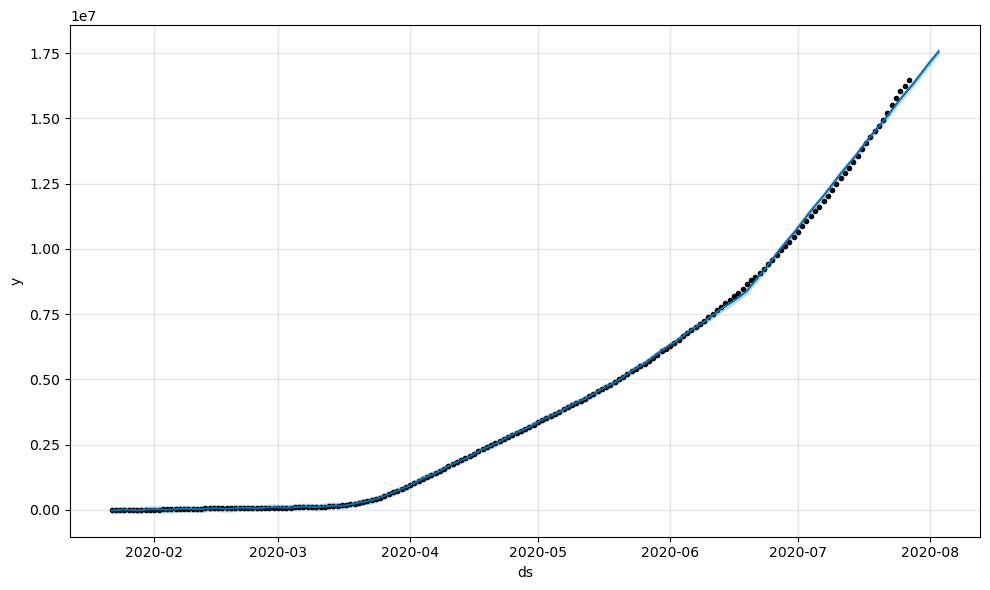

In [10]:
fig = model.plot(forecast)
plt.show()

## Conclusion

Analyzed COVID-19 trends using Pandas and Plotly, and used Facebook Prophet to forecast confirmed cases for the next 7 days.
This project improved my skills in data analysis, visualization, and time-series forecasting.
